# Tutorial Code for the PIC Project

## Imports
The first step to running the code includes importing functions and the datasets. To import the full dataset it takes about 90-150 seconds. If you want a quicker demonstration you can redirect the path to one of the other available datasets.

In [14]:
import importlib
import modules.pic_functions
import modules.ppv_functions

importlib.reload(modules.pic_functions)
importlib.reload(modules.ppv_functions)

from modules.pic_functions import *
from modules.ppv_functions import *

In [5]:
# Gets the dataset
dataset_path = '../dataset/000128/sub-Jenkins'
dataset = NWBDataset(dataset_path, "*train", split_heldout=False)
conditions = dataset.trial_info.set_index(['trial_type', 'trial_version']).index.unique().tolist()
neurons = dataset.data['spikes'].columns.tolist() #Gets the name of all neurons

# Resizes bins to 5ms
dataset.resample(5)

# Adds the reaching time to all trials
add_reachTime(dataset)

Other thing that is inmportant is to break the dataset into a train and validation sets to be able to train and improve models. Finaly we can report the performance with the Test set

In [6]:
train_sets, val_sets, test_dataset = generate_sets(dataset, 0.1, 1)
train_dataset = train_sets[0]
val_dataset = val_sets[0]

## Exploratory Data Analysis
Before any decoder can be applied we need to understand how the data is strcutured and what are some of its features. To do so we can inspect the neural activity by plotting the raster plot of a specific trial. Let's inspect trial 0

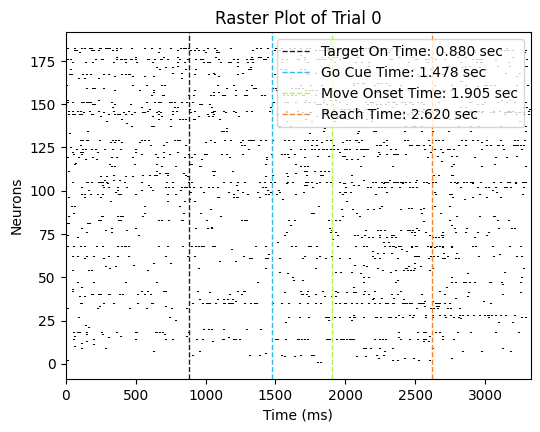

In [17]:
raster_plot(dataset, 0, neurons, ratio=6)

It is also important to check what was the monkeys behaviour. Let's inspect the trial design and the monkey's trajectory

## Population Vector Model
This is the first model used in this project. It is a more basic model with the intuit to be used as an introduction to many concepts such as Tuning Curves

### Building the Decoder
After understanding how the model works we can build our decoder

In [3]:
ppv_decoder = angle_decoder(train_dataset, 30, standard_neurons)

With the decoder we can visualize the tuning curves and how they fit to the data

IndexError: index 182 is out of bounds for axis 1 with size 182

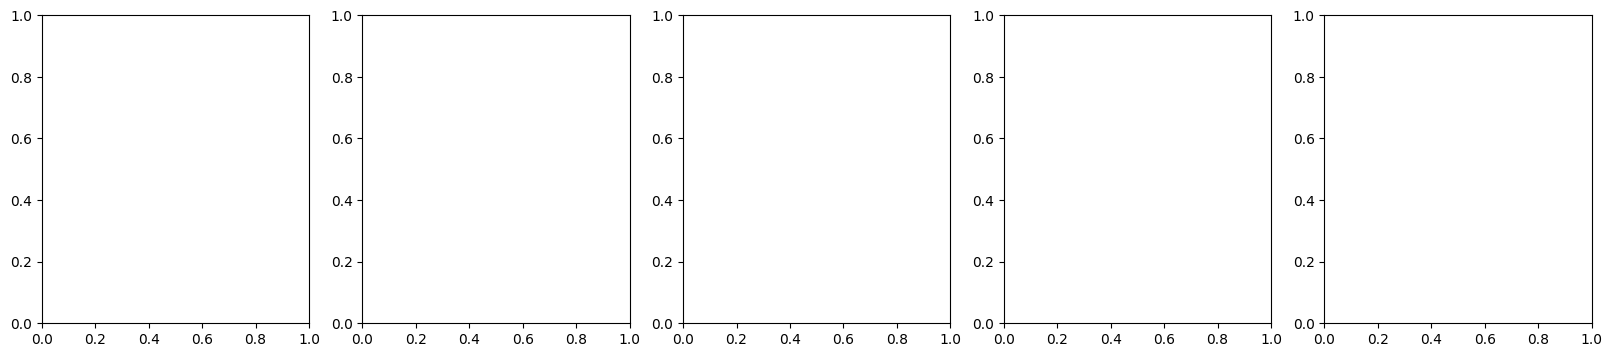

In [5]:
plot_tuning(train_dataset, 100, [182,182], standard_neurons, ppv_decoder)